### GitHub Repository: https://github.com/LucianaHamaji-2026408/CCT_ML_2026408

## Predicting Student Academic Outcomes Using Machine Learning

### Project Overview

Higher education institutions face challenges in understanding why some students complete their studies while others drop out or remain enrolled. Analysing student data can help identify patterns associated with academic progression and support more informed educational decisions.
This project explores how machine learning can be used to classify students' academic outcomes based on demographic, socioeconomic, enrollment, and academic performance information.
The analysis uses the Predict Students' Dropout and Academic Success dataset from the UCI Machine Learning Repository, containing 4,424 student records and 36 predictive features.


### Project Information

* **Domain:** Education
* **Problem Type:** Supervised Machine Learning – Multiclass Classification
* **Target Variable (Target):** Dropout / Enrolled / Graduate
* **Algorithms:** Random Forest and Logistic Regression
* **Dataset:** Predict Students' Dropout and Academic Success – UCI Machine Learning Repository


### Research Questions

The analysis focuses on three main questions:

* How accurately can machine learning models predict whether students will drop out, remain enrolled, or graduate?

* How does model performance vary across different training and testing proportions?

* Which student characteristics contribute most to predicting academic outcomes?


### Analytical Approach

The project follows a structured machine learning workflow, beginning with dataset exploration and preprocessing, followed by model training, validation, optimisation, and interpretation.
Two classification algorithms, Random Forest and Logistic Regression, are evaluated using three testing proportions: 5%, 15%, and 25%, with the remaining data used for training.
Five-fold stratified cross-validation is applied to assess model stability, while GridSearchCV is used to identify suitable hyperparameters.
The models are compared using accuracy, precision, recall, F1-score, and confusion matrices. Feature importance is also examined to identify relevant predictors.
The final evaluation considers predictive performance, overfitting, and generalisation to determine which approach is more suitable for this dataset.

### Practical Relevance

The findings may help educational institutions better understand patterns associated with student progression and academic difficulties.
By identifying relevant predictive factors, machine learning could support student monitoring and inform targeted academic support strategies.
However, predictions should be treated as decision-support information rather than definitive assessments of individual students.

## 1. Dataset Characterisation

### 1.1 Dataset Information

In [59]:
import pandas as pd

In [60]:
students_df = pd.read_csv("data.csv", sep=";")

In [61]:
students_df.columns = students_df.columns.str.strip()

In [62]:
students_df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [63]:
students_df.shape

(4424, 37)

In [64]:
students_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

### 1.2 Missing Values and Duplicated Records

In [66]:
students_df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [67]:
students_df.duplicated().sum()

np.int64(0)

### 1.3 Feature Characteristics

In [70]:
students_df.nunique().sort_values()

Daytime/evening attendance                          2
Displaced                                           2
Debtor                                              2
Educational special needs                           2
International                                       2
Scholarship holder                                  2
Gender                                              2
Tuition fees up to date                             2
Target                                              3
Marital status                                      6
Application order                                   8
Inflation rate                                      9
Curricular units 2nd sem (without evaluations)     10
Unemployment rate                                  10
GDP                                                10
Curricular units 1st sem (without evaluations)     11
Course                                             17
Previous qualification                             17
Application mode            

### 1.4 Descriptive Statistics

In [111]:
students_df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [71]:
students_df[["Age at enrollment",
             "Admission grade",
             "Curricular units 1st sem (grade)", 
             "Curricular units 2nd sem (grade)"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Age at enrollment,4424.0,23.265145,7.587816,17.0,19.00,20.000000,25.000000,70.000000
Admission grade,4424.0,126.978119,14.482001,95.0,117.90,126.100000,134.800000,190.000000
Curricular units 1st sem (grade),4424.0,10.640822,4.843663,0.0,11.00,12.285714,13.400000,18.875000
Curricular units 2nd sem (grade),4424.0,10.230206,5.210808,0.0,10.75,12.200000,13.333333,18.571429


### 1.5 Investigation of Zero Academic Grades

In [72]:
students_df[["Curricular units 1st sem (grade)",
             "Curricular units 2nd sem (grade)"]].eq(0).sum()

Curricular units 1st sem (grade)    718
Curricular units 2nd sem (grade)    870
dtype: int64

In [73]:
students_df.loc[students_df["Curricular units 1st sem (grade)"] == 0,
    "Curricular units 1st sem (evaluations)"].value_counts().sort_index()

Curricular units 1st sem (evaluations)
0     349
1       6
2       4
3       3
4      16
5      95
6      64
7      39
8      29
9      28
10     24
11     14
12     21
13      5
14     11
15      1
16      2
17      2
18      3
19      1
21      1
Name: count, dtype: int64

In [74]:
students_df.loc[students_df["Curricular units 2nd sem (grade)"] == 0,
    "Curricular units 2nd sem (evaluations)"].value_counts().sort_index()

Curricular units 2nd sem (evaluations)
0     401
1       1
2       3
4       7
5     138
6      89
7      49
8      43
9      30
10     42
11      6
12     33
13     13
14      4
15      3
16      4
17      2
19      1
20      1
Name: count, dtype: int64

### 1.6 Target Variable Distribution

In [109]:
students_df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

In [110]:
students_df["Target"].value_counts(normalize=True) * 100

Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64

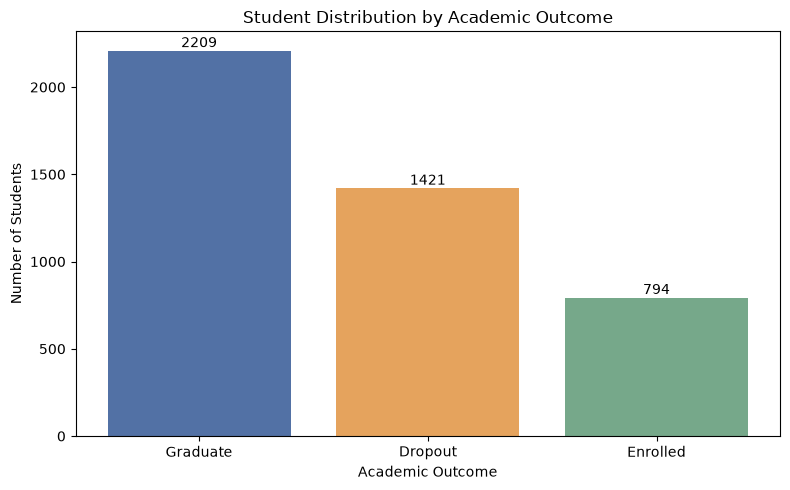

In [108]:
import matplotlib.pyplot as plt

# Count students in each class
class_counts = students_df['Target'].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_counts.index,
    class_counts.values,
    color=['#5271A5', '#E5A35D', '#76A88A']
)

plt.title('Student Distribution by Academic Outcome')
plt.xlabel('Academic Outcome')
plt.ylabel('Number of Students')

# Add values above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20,
        int(bar.get_height()),
        ha='center'
    )

plt.tight_layout()
plt.show()

### 1.7 Initial Observations

The Predict Students' Dropout and Academic Success dataset contains 4,424 observations and 37 columns. Of these, 7 are classified as float64, 29 as int64, and 1 as object. The target variable contains text labels, while some numerical features represent categories encoded as numbers.

No missing values or duplicate records were identified. However, the target variable shows a moderate class imbalance, with Graduate representing 49.93% of students, followed by Dropout (32.12%) and Enrolled (17.95%).

The investigation also identified zero grades in both semesters. Some students had no recorded assessments, while others had assessments recorded despite receiving a grade of zero. Therefore, these values cannot automatically be considered missing data.

## 2. Data Preprocessing

In [75]:
X = students_df.drop(columns=['Target'])
y = students_df['Target']

print('Features:', X.shape)
print('Target:', y.shape)

Features: (4424, 36)
Target: (4424,)


In [76]:
categorical_features = ['Marital status',
                        'Application mode',
                        'Course',
                        'Previous qualification',
                        'Nacionality',
                        "Mother's qualification",
                        "Father's qualification",
                        "Mother's occupation",
                        "Father's occupation"
                       ]

In [77]:
numerical_features = [
    'Previous qualification (grade)',
    'Admission grade',
    'Age at enrollment',
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

In [78]:
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print("Missing columns:", [
    col for col in numerical_features + categorical_features
    if col not in X.columns
])

Categorical features: 9
Numerical features: 18
Missing columns: []


In [79]:
test_sizes = [0.05, 0.15, 0.25]

In [80]:
from sklearn.model_selection import train_test_split

### 2.1 Discussion

During data preprocessing, the explanatory variables (X) were separated from the target variable (y). The 36 features were divided into three groups: nine categorical, 18 numerical, and nine remaining features, including binary indicators and one ordinal variable.

Categorical features were encoded using pd.get_dummies(), while StandardScaler was applied to the selected numerical features for Logistic Regression. The stratify=y parameter was used to preserve the class proportions in each training and testing split, and random_state=42 ensured reproducibility.

For cross-validation, preprocessing steps were included within pipelines so that the necessary transformations could be fitted separately on each training fold, reducing the risk of data leakage from validation data.

## 3. Model Training and Evaluation

### 3.1 Random Forest — Split Comparison

In [81]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [82]:
rf_results = []

for test_size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)

    X_train_encoded = pd.get_dummies(X_train, columns=categorical_features)

    X_test_encoded = pd.get_dummies(X_test, columns=categorical_features)

    X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

    rf_model = RandomForestClassifier(random_state=42)
    rf_model.fit(X_train_encoded, y_train)

    train_accuracy = accuracy_score(y_train, rf_model.predict(X_train_encoded))

    test_accuracy = accuracy_score(y_test, rf_model.predict(X_test_encoded))
    rf_results.append({'Test Size': test_size, 'Training Accuracy': train_accuracy, 'Testing Accuracy': test_accuracy})

rf_results_df = pd.DataFrame(rf_results)
rf_results_df

,Test Size,Training Accuracy,Testing Accuracy
0,0.05,1.0,0.806306
1,0.15,1.0,0.771084
2,0.25,1.0,0.758590


### 3.2 Random Forest Cross-Validation

In [83]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [84]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [85]:
from sklearn.base import BaseEstimator, TransformerMixin

class DummyEncoder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.columns_ = pd.get_dummies(
            X, columns=categorical_features
        ).columns
        return self

    def transform(self, X):
        encoded = pd.get_dummies(
            X, columns=categorical_features
        )
        return encoded.reindex(
            columns=self.columns_, fill_value=0
        )

In [86]:
from sklearn.pipeline import make_pipeline

rf_cv_model = make_pipeline(
    DummyEncoder(),
    RandomForestClassifier(random_state=42)
)

In [87]:
cv_results = []

for test_size in test_sizes:
    X_train_cv, X_test_cv, y_train_cv, y_test_cv = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    scores = cross_val_score(
        rf_cv_model,
        X_train_cv,
        y_train_cv,
        cv=cv,
        scoring='accuracy'
    )

    cv_results.append({
        'Test Size': test_size,
        'Mean CV Accuracy': scores.mean(),
        'CV Standard Deviation': scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df

,Test Size,Mean CV Accuracy,CV Standard Deviation
0,0.05,0.763924,0.005359
1,0.15,0.771543,0.011075
2,0.25,0.768533,0.006498


### 3.3 Logistic Regression Classifier

In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [89]:
from sklearn.compose import ColumnTransformer

scaler = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features)
    ],
    remainder='passthrough'
)

In [90]:
from sklearn.pipeline import make_pipeline

lr_model = make_pipeline(
    DummyEncoder(),
    scaler,
    LogisticRegression(max_iter=2000, random_state=42)
)

### 3.4 Logistic Regression — Split Comparison

In [91]:
lr_results = []

for test_size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    lr_model.fit(X_train, y_train)

    train_accuracy = accuracy_score(
        y_train, lr_model.predict(X_train)
    )

    test_accuracy = accuracy_score(
        y_test, lr_model.predict(X_test)
    )

    lr_results.append({
        'Test Size': test_size,
        'Training Accuracy': train_accuracy,
        'Testing Accuracy': test_accuracy
    })

lr_results_df = pd.DataFrame(lr_results)
lr_results_df

,Test Size,Training Accuracy,Testing Accuracy
0,0.05,0.804141,0.792793
1,0.15,0.803723,0.795181
2,0.25,0.811935,0.778481


### 3.5 Logistic Regression Cross-Validation

In [92]:
lr_cv_results = []

for test_size in test_sizes:
    X_train_cv, X_test_cv, y_train_cv, y_test_cv = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    scores = cross_val_score(
        lr_model,
        X_train_cv,
        y_train_cv,
        cv=cv,
        scoring='accuracy'
    )
    
    lr_cv_results.append({
        'Test Size': test_size,
        'Scores Mean': scores.mean(),
        'Scores Std': scores.std()
    })

lr_cv_results_df = pd.DataFrame(lr_cv_results)
lr_cv_results_df

,Test Size,Scores Mean,Scores Std
0,0.05,0.778207,0.011990
1,0.15,0.774202,0.009074
2,0.25,0.776372,0.010790


### 3.6 Discussion

The results show differences in how Random Forest and Logistic Regression performed across the three data splits. Random Forest achieved its highest testing accuracy with the 5% test split, but its 100% training accuracy across all splits suggests overfitting.

In contrast, Logistic Regression showed smaller differences between training and testing accuracy and outperformed Random Forest with the 15% and 25% test splits.

Cross-validation provided an additional assessment of model stability, with Logistic Regression achieving slightly higher average accuracy overall.

However, the results do not necessarily indicate that smaller test sets improve model performance, as fewer testing observations may produce less reliable accuracy estimates.

## 4. Hyperparameter Tuning

### 4.1 Random Forest — GridSearchCV

In [93]:
from sklearn.model_selection import GridSearchCV

In [94]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [95]:
param_grid = {
    'randomforestclassifier__n_estimators': [100, 200],
    'randomforestclassifier__max_depth': [10, 20],
    'randomforestclassifier__min_samples_split': [2, 5],
    'randomforestclassifier__min_samples_leaf': [1, 2]
}

In [96]:
rf_grid = GridSearchCV(
    estimator=rf_cv_model,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'randomforestclassifier__max_depth': [10, 20], 'randomforestclassifier__min_samples_leaf': [1, 2], 'randomforestclassifier__min_samples_split': [2, 5], 'randomforestclassifier__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to b

In [97]:
print("Best Parameters:", rf_grid.best_params_)
print("Best CV Accuracy:", rf_grid.best_score_)

Best Parameters: {'randomforestclassifier__max_depth': 20, 'randomforestclassifier__min_samples_leaf': 1, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__n_estimators': 100}
Best CV Accuracy: 0.7736570717258172


In [98]:
best_rf = rf_grid.best_estimator_

print("Training Accuracy:", best_rf.score(X_train, y_train))
print("Testing Accuracy:", best_rf.score(X_test, y_test))

Training Accuracy: 0.9617239300783604
Testing Accuracy: 0.7640144665461122


### 4.2 Logistic Regression — GridSearchCV

In [99]:
lr_param_grid = {
    'logisticregression__C': [0.01, 0.1, 1, 10],
    'logisticregression__solver': ['lbfgs']
}

In [100]:
lr_grid = GridSearchCV(
    estimator=lr_model,
    param_grid=lr_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

In [101]:
lr_grid.fit(X_train, y_train)

print("Best Parameters:", lr_grid.best_params_)
print("Best CV Accuracy:", lr_grid.best_score_)

Best Parameters: {'logisticregression__C': 1, 'logisticregression__solver': 'lbfgs'}
Best CV Accuracy: 0.7763720038525141


In [102]:
best_lr = lr_grid.best_estimator_

print("Training Accuracy:", best_lr.score(X_train, y_train))
print("Testing Accuracy:", best_lr.score(X_test, y_test))

Training Accuracy: 0.8119349005424955
Testing Accuracy: 0.7784810126582279


### 4.3 Discussion

For the hyperparameter tuning stage, GridSearchCV with five-fold cross-validation was employed to test different configurations and select the best hyperparameters. To ensure a consistent comparison between models, the dataset was split into 75% for training and 25% for testing.

The results showed that Logistic Regression achieved slightly higher testing accuracy than Random Forest. However, Random Forest continued to show signs of overfitting, with a considerable difference between training and testing performance.

## 5. Model Evaluation and Interpretation

### 5.1 Confusion Matrix

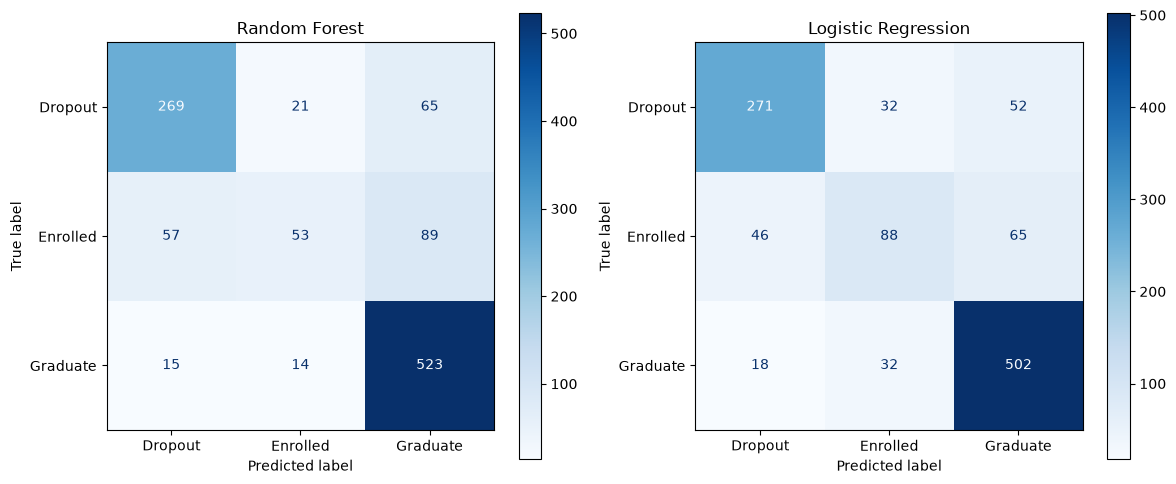

In [103]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

rf_predictions = best_rf.predict(X_test)
lr_predictions = best_lr.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    ax=axes[0],
    cmap='Blues'
)
axes[0].set_title('Random Forest')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    ax=axes[1],
    cmap='Blues'
)
axes[1].set_title('Logistic Regression')

plt.tight_layout()
plt.show()

### 5.2 Classification Report

In [104]:
from sklearn.metrics import classification_report

print("Random Forest Classification Report:")
print(classification_report(y_test, rf_predictions))

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, lr_predictions))

Random Forest Classification Report:
              precision    recall  f1-score   support

     Dropout       0.79      0.76      0.77       355
    Enrolled       0.60      0.27      0.37       199
    Graduate       0.77      0.95      0.85       552

    accuracy                           0.76      1106
   macro avg       0.72      0.66      0.66      1106
weighted avg       0.75      0.76      0.74      1106


Logistic Regression Classification Report:
              precision    recall  f1-score   support

     Dropout       0.81      0.76      0.79       355
    Enrolled       0.58      0.44      0.50       199
    Graduate       0.81      0.91      0.86       552

    accuracy                           0.78      1106
   macro avg       0.73      0.71      0.71      1106
weighted avg       0.77      0.78      0.77      1106



### 5.3 Feature Importance

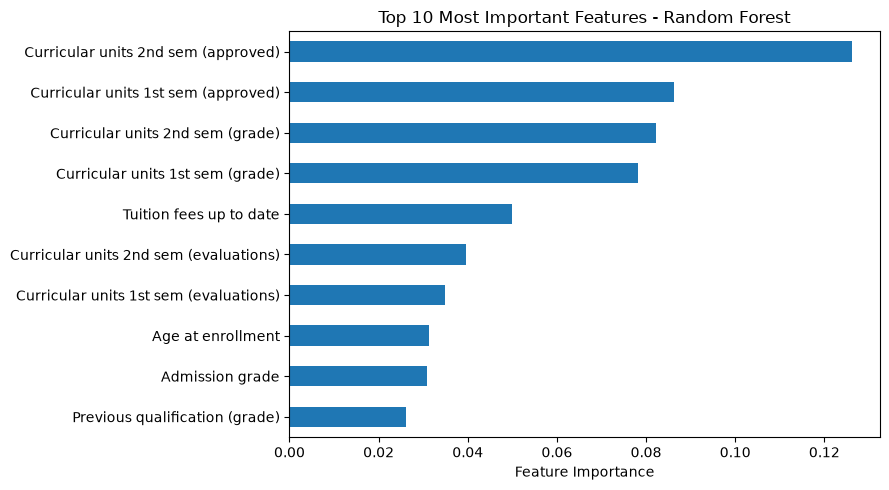

In [105]:
import pandas as pd
import matplotlib.pyplot as plt

feature_names = best_rf.named_steps['dummyencoder'].columns_

importances = best_rf.named_steps[
    'randomforestclassifier'
].feature_importances_

feature_importance = pd.Series(
    importances,
    index=feature_names
).sort_values(ascending=False)

feature_importance.head(10).sort_values().plot(
    kind='barh',
    figsize=(9, 5)
)

plt.title('Top 10 Most Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.tight_layout()
plt.show()

### 5.4 Training and Testing Accuracy of Tuned Models

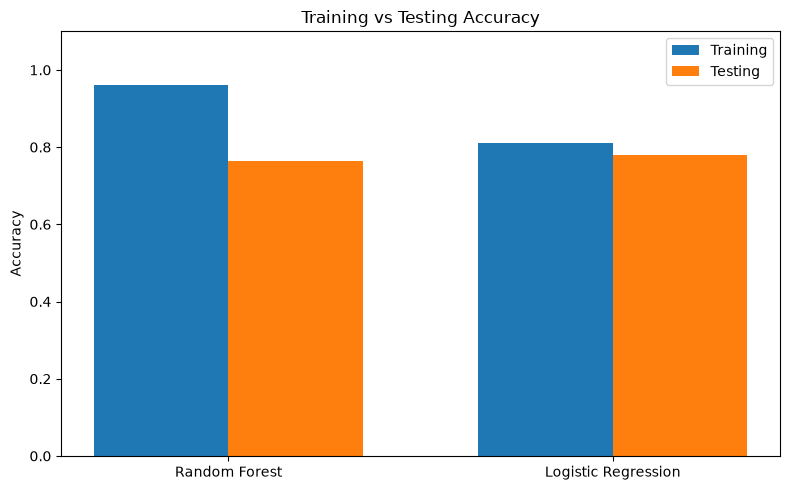

In [106]:
import matplotlib.pyplot as plt
import numpy as np

models = ['Random Forest', 'Logistic Regression']

training_accuracy = [
    best_rf.score(X_train, y_train),
    best_lr.score(X_train, y_train)
]

testing_accuracy = [
    best_rf.score(X_test, y_test),
    best_lr.score(X_test, y_test)
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, training_accuracy, width, label='Training')
plt.bar(x + width/2, testing_accuracy, width, label='Testing')

plt.xticks(x, models)
plt.ylabel('Accuracy')
plt.title('Training vs Testing Accuracy')
plt.ylim(0, 1.1)
plt.legend()

plt.tight_layout()
plt.show()

### 5.5 Discussion

Random Forest feature importance was used to identify the ten most influential variables in the model's predictions. Academic performance during the first two semesters emerged as particularly important, especially the number of approved curricular units and semester grades. Other relevant features included tuition fee payment status, the number of assessments, age at enrolment, and admission grade.

These findings suggest that academic progression plays an important role in predicting student outcomes. However, feature importance does not establish causality or indicate whether a variable increases the likelihood of dropping out or graduating.

The "Training vs Testing Accuracy" graph shows that the Random Forest model has a considerable difference between training and testing accuracy (19.77 percentage points), indicating overfitting. In contrast, Logistic Regression shows a much smaller difference (3.34 percentage points), suggesting better generalisation. Furthermore, Logistic Regression achieved slightly higher testing accuracy, indicating that it performed better on unseen data in this experiment.

## 6. Conclusion